### Jag importerar alla paket som behövs och skapar en dataframe. Skapar även en repeterbar simulering och importerar 3 moduler för att få en mer strukurerad kod 

In [21]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import sys
sys.path.append("./src")
from src.health_analyzer import Healthanalyzer
import src.metrics as metrics
import src.viz as viz
from sklearn.linear_model import LinearRegression

np.random.seed(42)

df = pd.read_csv("health_study_dataset.csv")

df.info()

print(df.describe())

print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    object 
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    object 
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 56.4+ KB
             id         age      height      weight  systolic_bp  cholesterol  \
count  800.0000  800.000000  800.000000  800.000000   800.000000   800.000000   
mean   400.5000   49.426250  171.849250   73.413000   149.178625     4.929150   
std    231.0844   14.501118    9.804259   13.685059    12.793360     0.848413   
min      1.0000   18.000000  144.400000   33.70

## Här använder jag klassen för att analysera datan som returnerar några nyckeltal från datasetet

In [22]:
analyzer = Healthanalyzer(df)
analyzer.calc_stats()

,age,height,weight,systolic_bp,cholesterol
mean,49.42625,171.84925,73.413,149.178625,4.92915
median,50.00000,171.35000,73.200,149.400000,4.97000
min,18.00000,144.40000,33.700,106.800000,2.50000
max,90.00000,200.40000,114.400,185.900000,7.88000


## Här visas ett histogram med fördelning över kolesterolhalt för varje person med hjälp av en funktion från en modul

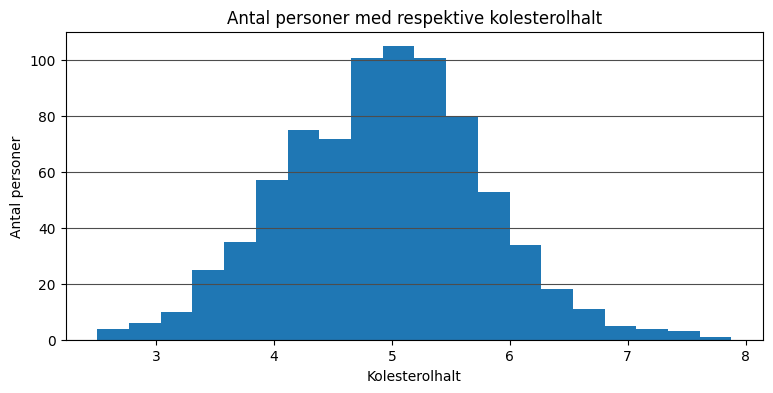

In [23]:
viz.hist_cholesterol(df)

## Här visas ett stapeldiagram över personer som är rökare eller ej

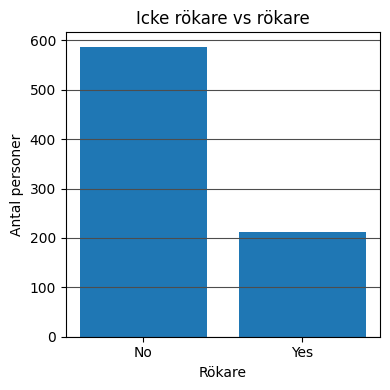

In [24]:
fig, ax = plt.subplots(figsize=(4,4))

ax.bar(df["smoker"].value_counts().index, height=df["smoker"].value_counts(), width=0.8)
ax.set_title("Icke rökare vs rökare")
ax.set_xlabel("Rökare")
ax.set_ylabel("Antal personer")
ax.grid(True, axis="y", color="0.3")
plt.tight_layout()
plt.show()

## Här visas en boxplot med Längd över kön med hjälp av en funktion från en modul

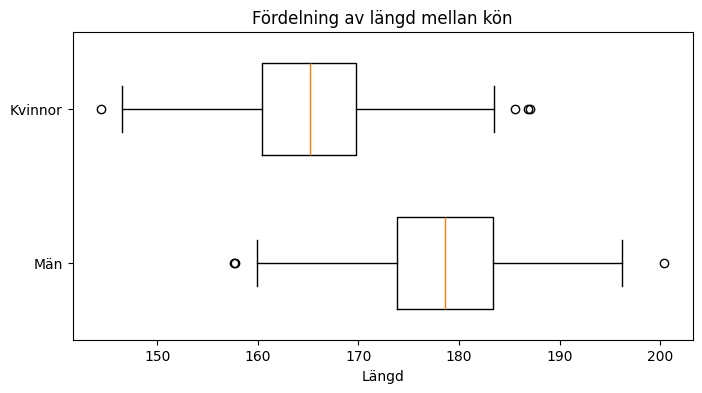

In [25]:
viz.box_length(df)

## En beräkning är gjord på antalet och andelen personer som har sjukdomen med hjälp av en funktion från en modul

In [26]:
calc_disease = metrics.calc_disease(df)
print(f"Antalet sjuka personer:", calc_disease[0])
print()
print(f"Andelen sjuka:")
print(pd.DataFrame(calc_disease[1]))

Antalet sjuka personer: 47

Andelen sjuka:
     proportion
Nej     0.94125
Ja      0.05875


## Här visas en simulering över 1000 slumpade personer där sannolikheten för sjukdom är samma som datasetet

In [27]:
df_sick_proportion = df["disease"].value_counts(normalize=True)
df_sick_proportion.index = ["Nej", "Ja"]
df_sim_prob = np.random.choice(["Nej", "Ja"], size=1000, p=df_sick_proportion)
df_sim_prob = pd.Series(df_sim_prob).value_counts(normalize=True)
print(f"Andelen sjuka:")
print(df_sim_prob)

Andelen sjuka:
Nej    0.944
Ja     0.056
Name: proportion, dtype: float64


## Här jämför jag den verkliga andelen med den simulerade andelen

In [28]:
comp_real_sim = pd.DataFrame({"Verklig": df_sick_proportion,
                              "Simulerad": df_sim_prob})
comp_real_sim


,Verklig,Simulerad
Nej,0.94125,0.944
Ja,0.05875,0.056


## Här beräknar jag konfidensintervallet för medelvärdet av blodtrycket med metoden: student's t-distribution. Det görs med hjälp av en funktion från en modul. Det är i det intervallet som ungefär 95% av stickprovens sanna medelvärde kommer vara

In [29]:
calc_bp_ci = metrics.calc_bp_ci(df)

print(f"Undre gräns: {calc_bp_ci[0]}\nÖvre gräns: {calc_bp_ci[1]}")

Undre gräns: 148.29076170667028
Övre gräns: 150.06648829332974


## Här testar jag hypotesen "Rökare har högre medel-blodtryck än icke-rökare"

In [30]:
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

print("Genomsnitt rökare:", smokers.mean())
print("genomsnitt icke-rökare:", non_smokers.mean())
print()

result = stats.ttest_ind(smokers,
                         non_smokers,
                         equal_var=False,
                         alternative="greater")

print(result)

Genomsnitt rökare: 149.524882629108
genomsnitt icke-rökare: 149.05298126064736

TtestResult(statistic=np.float64(0.4503433193393224), pvalue=np.float64(0.3263669371699499), df=np.float64(360.15254973870043))


### P-värdet är ca 0,32 och om vi jämför det med signifikansnivån 0,05 så kan jag inte förkasta nollhypotesen. Det finns inte tillräckligt med statistiskt stöd eller bevis som tyder på att hypotesen är sann.

## 

In [ ]:
x_2d = df[["weight"]].values
y_1d = df["systolic_bp"].values

